# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [1]:
import random

class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __repr__(self):
        return f"{self.rank} of {self.suit}"


class Deck:
    def __init__(self, n_decks=6):
        self.n_decks = n_decks
        self.cards = []
        self.shuffle()

    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        self.cards = []

        for _ in range(self.n_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))

        random.shuffle(self.cards)

        plastic_position = random.randint(
            int(len(self.cards) * 0.6),
            int(len(self.cards) * 0.9)
        )

        self.cards.insert(plastic_position, "PLASTIC")

    def draw(self):
        card = self.cards.pop()

        if card == "PLASTIC":
            self.shuffle()
            card = self.cards.pop()

        return card

In [2]:
deck = Deck(6)

print("Cards in deck:", len(deck.cards))

for i in range(5):
    print(deck.draw())

Cards in deck: 313
3 of Diamonds
K of Diamonds
8 of Spades
3 of Spades
J of Diamonds


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [3]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def value(self):
        pass

    def clear(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def hit_or_stay(self, shown_cards):
        pass

    def bet(self):
        pass


class Dealer(Player):
    def hit_or_stay(self, shown_cards):
        pass


class HumanPlayer(Player):
    def hit_or_stay(self, shown_cards):
        pass


class Game:
    def __init__(self, players):
        self.deck = Deck(6)
        self.players = players
        self.dealer = Dealer("Dealer")
        self.shown_cards = []

    def deal(self):
        pass

    def play_hand(self):
        pass

    def determine_winner(self):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [4]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def value(self):
        total = 0
        aces = 0

        for card in self.cards:
            if card.rank in ["J", "Q", "K"]:
                total += 10
            elif card.rank == "A":
                total += 11
                aces += 1
            else:
                total += int(card.rank)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def clear(self):
        self.cards = []


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def hit_or_stay(self, shown_cards):
        pass

    def bet(self):
        return 10


class Dealer(Player):
    def hit_or_stay(self, shown_cards):
        return self.hand.value() <= 16


class HumanPlayer(Player):
    def hit_or_stay(self, shown_cards):
        choice = input("Hit or stay? ").lower()
        return choice == "hit"


class Game:
    def __init__(self, players):
        self.deck = Deck(6)
        self.players = players
        self.dealer = Dealer("Dealer")
        self.shown_cards = []

    def deal(self):
        self.dealer.hand.clear()

        for player in self.players:
            player.hand.clear()

        for i in range(2):
            for player in self.players:
                card = self.deck.draw()
                player.hand.add_card(card)
                self.shown_cards.append(card)

            card = self.deck.draw()
            self.dealer.hand.add_card(card)
            self.shown_cards.append(card)

    def play_hand(self):
        for player in self.players:
            while player.hit_or_stay(self.shown_cards):
                card = self.deck.draw()
                player.hand.add_card(card)
                self.shown_cards.append(card)

                if player.hand.value() > 21:
                    break

        while self.dealer.hit_or_stay(self.shown_cards):
            card = self.deck.draw()
            self.dealer.hand.add_card(card)
            self.shown_cards.append(card)

    def determine_winner(self):
        dealer_value = self.dealer.hand.value()

        for player in self.players:
            player_value = player.hand.value()

            if player_value > 21:
                print(player.name, "loses")
            elif dealer_value > 21 or player_value > dealer_value:
                print(player.name, "wins")
            elif player_value == dealer_value:
                print(player.name, "push")
            else:
                print(player.name, "loses")

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [5]:
players = [
    Dealer("Player 1"),
    Dealer("Player 2"),
    Dealer("Player 3")
]

game = Game(players)

for round_number in range(3):
    print("Round", round_number + 1)

    game.deal()
    game.play_hand()

    for player in players:
        print(player.name, player.hand.cards, "Value:", player.hand.value())

    print("Dealer:", game.dealer.hand.cards,
          "Value:", game.dealer.hand.value())

    game.determine_winner()
    print()

Round 1
Player 1 [3 of Clubs, 8 of Clubs, 5 of Hearts, 6 of Hearts] Value: 22
Player 2 [3 of Hearts, J of Hearts, J of Hearts] Value: 23
Player 3 [A of Diamonds, J of Diamonds] Value: 21
Dealer: [4 of Hearts, Q of Spades, 10 of Clubs] Value: 24
Player 1 loses
Player 2 loses
Player 3 wins

Round 2
Player 1 [5 of Diamonds, 2 of Clubs, A of Diamonds] Value: 18
Player 2 [3 of Clubs, 2 of Hearts, 8 of Clubs, A of Clubs, 10 of Hearts] Value: 24
Player 3 [9 of Diamonds, 4 of Clubs, 7 of Spades] Value: 20
Dealer: [9 of Spades, 4 of Hearts, K of Hearts] Value: 23
Player 1 wins
Player 2 loses
Player 3 wins

Round 3
Player 1 [6 of Spades, 9 of Hearts, 9 of Spades] Value: 24
Player 2 [4 of Spades, Q of Spades, 4 of Clubs] Value: 18
Player 3 [9 of Diamonds, 4 of Diamonds, 3 of Diamonds, 3 of Clubs] Value: 19
Dealer: [Q of Clubs, 6 of Spades, Q of Spades] Value: 26
Player 1 loses
Player 2 wins
Player 3 wins



6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [6]:
class CardCountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def hit_or_stay(self, shown_cards):
        count = 0

        for card in shown_cards:
            if card.rank in ["2", "3", "4", "5", "6"]:
                count += 1
            elif card.rank in ["10", "J", "Q", "K", "A"]:
                count -= 1

        return count < self.threshold

In [7]:
counter = CardCountingPlayer("Counter")

cards_seen = [
    Card("2", "Hearts"),
    Card("5", "Clubs"),
    Card("K", "Spades"),
    Card("A", "Diamonds")
]

print(counter.hit_or_stay(cards_seen))

False


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [8]:
strategy_player = CardCountingPlayer("Counter", chips=100)

other_players = [
    Dealer("Player 1", chips=100),
    Dealer("Player 2", chips=100),
    Dealer("Player 3", chips=100)
]

players = [strategy_player] + other_players
game = Game(players)

starting_chips = strategy_player.chips

for round_number in range(50):

    if strategy_player.chips <= 0:
        break

    game.deal()
    game.play_hand()

    dealer_value = game.dealer.hand.value()
    player_value = strategy_player.hand.value()

    bet = strategy_player.bet()

    if player_value > 21:
        strategy_player.chips -= bet
    elif dealer_value > 21 or player_value > dealer_value:
        strategy_player.chips += bet
    elif player_value < dealer_value:
        strategy_player.chips -= bet

print("Starting chips:", starting_chips)
print("Ending chips:", strategy_player.chips)
print("Winnings:", strategy_player.chips - starting_chips)

Starting chips: 100
Ending chips: 0
Winnings: -100


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


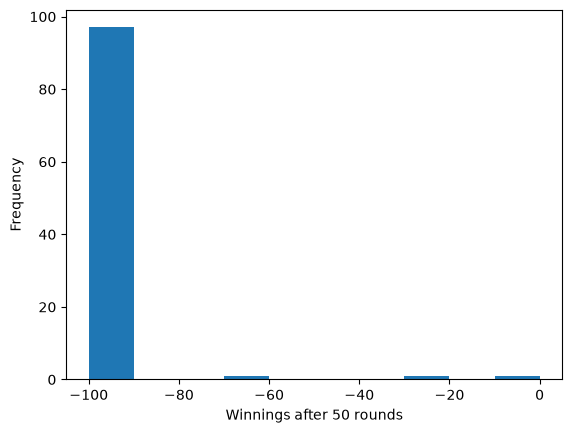

Average winnings per round: -1.96
Standard deviation: 12.409673645990857
Probability of net winning: 0.0
Probability of net losing: 0.99


In [9]:
import matplotlib.pyplot as plt
import numpy as np

winnings = []

for game_number in range(100):
    strategy_player = CardCountingPlayer("Counter", chips=100)

    other_players = [
        Dealer("Player 1", chips=100),
        Dealer("Player 2", chips=100),
        Dealer("Player 3", chips=100)
    ]

    players = [strategy_player] + other_players
    game = Game(players)

    for round_number in range(50):
        if strategy_player.chips <= 0:
            break

        game.deal()
        game.play_hand()

        dealer_value = game.dealer.hand.value()
        player_value = strategy_player.hand.value()
        bet = strategy_player.bet()

        if player_value > 21:
            strategy_player.chips -= bet
        elif dealer_value > 21 or player_value > dealer_value:
            strategy_player.chips += bet
        elif player_value < dealer_value:
            strategy_player.chips -= bet

    winnings.append(strategy_player.chips - 100)

plt.hist(winnings)
plt.xlabel("Winnings after 50 rounds")
plt.ylabel("Frequency")
plt.show()

print("Average winnings per round:", np.mean(winnings) / 50)
print("Standard deviation:", np.std(winnings))
print("Probability of net winning:", np.mean(np.array(winnings) > 0))
print("Probability of net losing:", np.mean(np.array(winnings) < 0))

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [10]:
thresholds = [-4, -2, 0, 2, 4]
average_winnings = []

for threshold in thresholds:
    results = []

    for game_number in range(100):
        strategy_player = CardCountingPlayer(
            "Counter",
            chips=100,
            threshold=threshold
        )

        other_players = [
            Dealer("Player 1", chips=100),
            Dealer("Player 2", chips=100),
            Dealer("Player 3", chips=100)
        ]

        game = Game([strategy_player] + other_players)

        for round_number in range(50):
            if strategy_player.chips <= 0:
                break

            game.deal()
            game.play_hand()

            dealer_value = game.dealer.hand.value()
            player_value = strategy_player.hand.value()
            bet = strategy_player.bet()

            if player_value > 21:
                strategy_player.chips -= bet
            elif dealer_value > 21 or player_value > dealer_value:
                strategy_player.chips += bet
            elif player_value < dealer_value:
                strategy_player.chips -= bet

        results.append(strategy_player.chips - 100)

    average = np.mean(results)
    average_winnings.append(average)

    print("Threshold:", threshold,
          "Average winnings:", average)

best_index = np.argmax(average_winnings)

print("Best threshold:", thresholds[best_index])

Threshold: -4 Average winnings: -90.9
Threshold: -2 Average winnings: -94.2
Threshold: 0 Average winnings: -94.5
Threshold: 2 Average winnings: -94.4
Threshold: 4 Average winnings: -99.1
Best threshold: -4


Of the thresholds tested, -4 performed best because it had the highest average winnings.

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [11]:
class AggressivePlayer(Player):
    def hit_or_stay(self, shown_cards):
        return self.hand.value() < 20

In [14]:
aggressive_results = []

for game_number in range(100):
    aggressive_player = AggressivePlayer("Aggressive", chips=100)

    other_players = [
        Dealer("Player 1", chips=100),
        Dealer("Player 2", chips=100),
        Dealer("Player 3", chips=100)
    ]

    game = Game([aggressive_player] + other_players)

    for round_number in range(50):
        if aggressive_player.chips <= 0:
            break

        game.deal()
        game.play_hand()

        dealer_value = game.dealer.hand.value()
        player_value = aggressive_player.hand.value()
        bet = aggressive_player.bet()

        if player_value > 21:
            aggressive_player.chips -= bet
        elif dealer_value > 21 or player_value > dealer_value:
            aggressive_player.chips += bet
        elif player_value < dealer_value:
            aggressive_player.chips -= bet

    aggressive_results.append(aggressive_player.chips - 100)

print("Average winnings:", np.mean(aggressive_results))
print("Average winnings per round:", np.mean(aggressive_results) / 50)
print("Probability of net winning:",
      np.mean(np.array(aggressive_results) > 0))
print("Probability of net losing:",
      np.mean(np.array(aggressive_results) < 0))

Average winnings: -98.4
Average winnings per round: -1.9680000000000002
Probability of net winning: 0.0
Probability of net losing: 1.0


actually, after testing this it is a terrible idea because the average winning was -98.4 chips , next time I would probably choose a different strategy instead of doing such an agressive approach